In [1]:
!pip install -q lime shap

In [2]:
import os, random, time, hashlib, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (accuracy_score, roc_auc_score, roc_curve, auc,
                             confusion_matrix, multilabel_confusion_matrix, classification_report)
from sklearn.preprocessing import label_binarize
warnings.filterwarnings("ignore")

DATA_DIR      = "/kaggle/input/datasets/workshops11/medetec-dataset"
OUT_DIR       = "/kaggle/working"
IMG_SIZE      = 224
BATCH_SIZE    = 16
EPOCHS        = 50
LR_HEAD       = 1e-3
LR_BACKBONE   = 1e-4
WEIGHT_DECAY  = 1e-4
PATIENCE      = 5      # early stopping patience
LR_PATIENCE   = 2      # ReduceLROnPlateau patience
LR_FACTOR     = 0.5
FREEZE_EPOCHS = 2      # pehle 2 epoch backbone freeze
N_FOLDS       = 5
MIN_IMAGES    = 10     # is se kam images wali class drop
NUM_WORKERS   = 2
PRETRAINED    = True
LIME_SAMPLES  = 600
SHAP_NSAMPLES = 50
SEED          = 42

DEVICE  = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
os.makedirs(OUT_DIR, exist_ok=True)

def seed_everything(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.benchmark = True
seed_everything()
print("Device:", DEVICE, "| torch", torch.__version__)

Device: cuda | torch 2.11.0+cu128


Dropped classes (<10 images): {'malignant-wound-images': np.int64(9), 'haemangioma': np.int64(6), 'epidermolysis-bullosa': np.int64(5), 'pilonidal-sinus': np.int64(3)}
Dataset root      : /kaggle/input/datasets/workshops11/medetec-dataset/medetec-dataset
Duplicates removed: 2
Number of classes : 11
Number of samples : 569


,Samples
label,
abdominal-wounds,12
burns,19
extravasation-wound-images,18
foot-ulcers,48
leg-ulcer-images,135
meningitis,24
miscellaneous,56
orthopaedic-wounds,49
pressure-ulcer-images-a,100


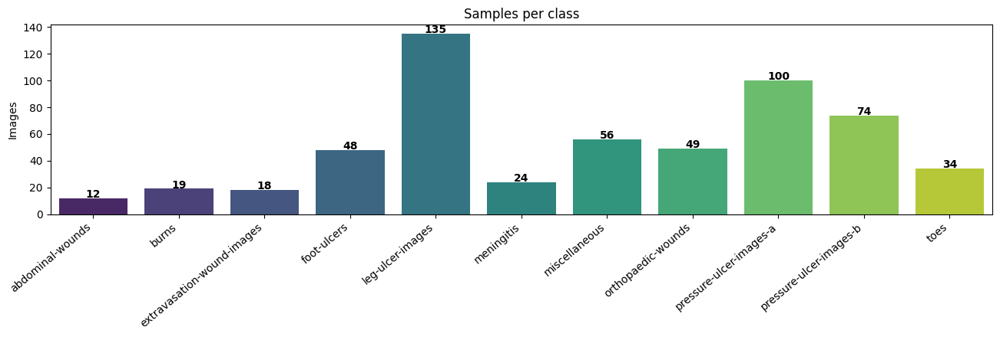

In [3]:
IMG_EXT     = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp", ".gif"}
SPLIT_NAMES = {"train", "test", "val", "valid", "validation", "training", "testing"}
SKIP_NAMES  = {"mask", "masks", "label", "labels", "gt", "groundtruth", "annotations"}

if not os.path.isdir(DATA_DIR):
    DATA_DIR = "/kaggle/input"

def has_images(d):
    return any(p.suffix.lower() in IMG_EXT for p in Path(d).rglob("*"))

def find_root(base):
    best, best_n = base, 0
    for d, subdirs, _ in os.walk(base):
        n = sum(1 for s in subdirs if s.lower() not in SKIP_NAMES and has_images(os.path.join(d, s)))
        if n > best_n:
            best, best_n = d, n
    if os.path.basename(best).lower() in SPLIT_NAMES:
        best = os.path.dirname(best)
    return best

ROOT = find_root(DATA_DIR)
subs = [s for s in sorted(os.listdir(ROOT)) if os.path.isdir(os.path.join(ROOT, s))]
split_dirs = [s for s in subs if s.lower() in SPLIT_NAMES]
bases = [os.path.join(ROOT, s) for s in split_dirs] if split_dirs else [ROOT]

records, seen, n_dup = [], set(), 0
for b in bases:
    for c in sorted(os.listdir(b)):
        cdir = os.path.join(b, c)
        if not os.path.isdir(cdir) or c.lower() in SKIP_NAMES:
            continue
        for p in sorted(Path(cdir).rglob("*")):
            if p.suffix.lower() not in IMG_EXT or any(x.lower() in SKIP_NAMES for x in p.parts):
                continue
            h = hashlib.md5(p.read_bytes()).hexdigest()
            if h in seen:
                n_dup += 1; continue
            seen.add(h)
            records.append((str(p), c.strip()))

df = pd.DataFrame(records, columns=["path", "label"])
cnt = df.label.value_counts()
small = cnt[cnt < MIN_IMAGES]
if len(small):
    print("Dropped classes (<%d images):" % MIN_IMAGES, dict(small))
df = df[df.label.isin(cnt[cnt >= MIN_IMAGES].index)].reset_index(drop=True)

CLASSES     = sorted(df.label.unique())
NUM_CLASSES = len(CLASSES)
cls2idx     = {c: i for i, c in enumerate(CLASSES)}
df["y"]     = df.label.map(cls2idx)

print("Dataset root      :", ROOT)
print("Duplicates removed:", n_dup)
print("Number of classes :", NUM_CLASSES)
print("Number of samples :", len(df))
class_table = df.label.value_counts().reindex(CLASSES).rename("Samples").to_frame()
class_table.loc["TOTAL"] = class_table.Samples.sum()
display(class_table)

plt.figure(figsize=(max(8, NUM_CLASSES * 1.2), 4.5))
ax = sns.barplot(x=CLASSES, y=[cnt[c] for c in CLASSES], palette="viridis")
for i, c in enumerate(CLASSES):
    ax.text(i, cnt[c] + 0.5, cnt[c], ha="center", fontweight="bold")
plt.xticks(rotation=40, ha="right"); plt.ylabel("Images"); plt.title("Samples per class")
plt.tight_layout(); plt.show()

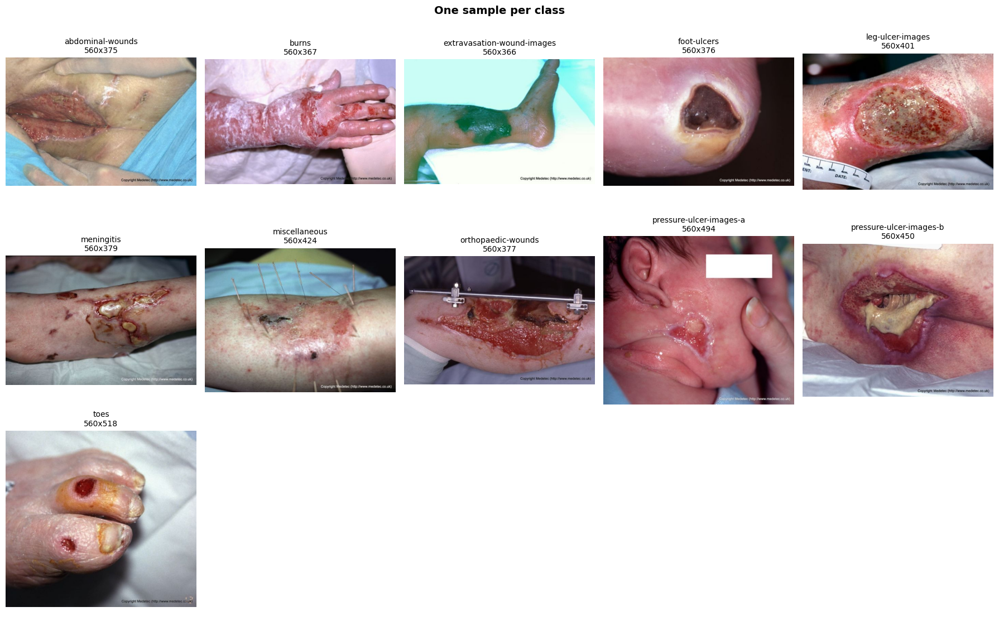

In [4]:
ncol = min(5, NUM_CLASSES); nrow = int(np.ceil(NUM_CLASSES / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.6 * ncol, 3.8 * nrow))
axes = np.array(axes).reshape(-1)
for ax in axes: ax.axis("off")
for i, c in enumerate(CLASSES):
    p = df[df.label == c].sample(1, random_state=SEED).path.iloc[0]
    img = Image.open(p).convert("RGB")
    axes[i].imshow(img); axes[i].set_title(f"{c}\n{img.size[0]}x{img.size[1]}", fontsize=10)
plt.suptitle("One sample per class", fontsize=14, fontweight="bold"); plt.tight_layout(); plt.show()

In [5]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df.y, random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df.y, random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]
print(f"Train: {len(train_df)} ({len(train_df)/len(df):.1%}) | Val: {len(val_df)} ({len(val_df)/len(df):.1%}) | Test: {len(test_df)} ({len(test_df)/len(df):.1%})")

Train: 398 (69.9%) | Val: 85 (14.9%) | Test: 86 (15.1%)


,Train,Val,Test,Total
label,,,,
abdominal-wounds,8,2,2,12
burns,13,3,3,19
extravasation-wound-images,13,3,2,18
foot-ulcers,34,7,7,48
leg-ulcer-images,94,20,21,135
meningitis,17,4,3,24
miscellaneous,39,8,9,56
orthopaedic-wounds,34,7,8,49
pressure-ulcer-images-a,70,15,15,100


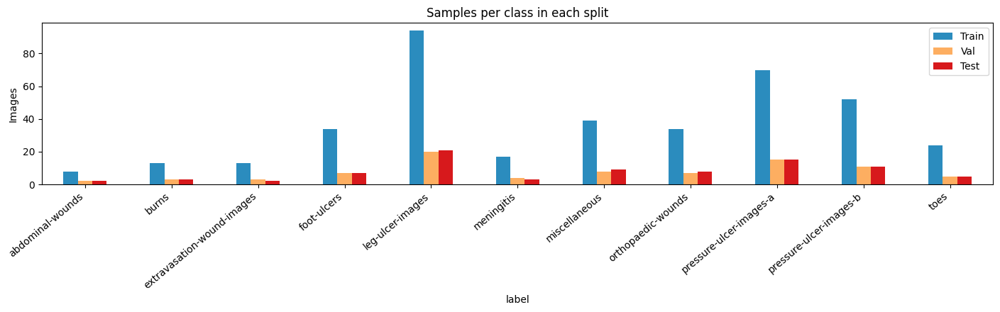

In [6]:
split_counts = pd.DataFrame({
    "Train": train_df.label.value_counts(),
    "Val":   val_df.label.value_counts(),
    "Test":  test_df.label.value_counts(),
}).reindex(CLASSES).fillna(0).astype(int)
split_counts["Total"] = split_counts.sum(1)
split_counts.loc["TOTAL"] = split_counts.sum()
display(split_counts)

split_counts.drop("TOTAL")[["Train", "Val", "Test"]].plot(kind="bar", figsize=(max(9, NUM_CLASSES * 1.3), 4.5), color=["#2b8cbe", "#fdae61", "#d7191c"])
plt.xticks(rotation=40, ha="right"); plt.ylabel("Images"); plt.title("Samples per class in each split")
plt.tight_layout(); plt.show()

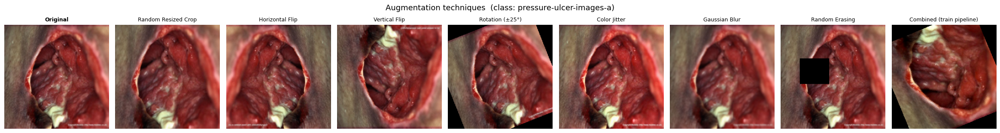

In [11]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(25),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.2, hue=0.02),
    transforms.RandomApply([transforms.GaussianBlur(5, sigma=(0.5, 1.5))], p=0.3),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.12)),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
disp_tf = transforms.Resize((IMG_SIZE, IMG_SIZE))

def denorm(t):
    t = t.clone().cpu() * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]
    return t.clamp(0, 1).permute(1, 2, 0).numpy()

AUGS = [
    ("Random Resized Crop",   transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0))),
    ("Horizontal Flip",       transforms.RandomHorizontalFlip(p=1.0)),
    ("Vertical Flip",         transforms.RandomVerticalFlip(p=1.0)),
    ("Rotation (±25°)",       transforms.RandomRotation(25)),
    ("Color Jitter",          transforms.ColorJitter(0.25, 0.25, 0.2, 0.02)),
    ("Gaussian Blur",         transforms.GaussianBlur(5, sigma=(1.0, 1.5))),
    ("Random Erasing",        transforms.Compose([transforms.ToTensor(), transforms.RandomErasing(p=1.0, scale=(0.05, 0.12)), transforms.ToPILImage()])),
]
orig = disp_tf(Image.open(train_df.path.iloc[5]).convert("RGB"))
torch.manual_seed(SEED)
panels = [("Original", np.array(orig))] + [(n, np.array(t(orig))) for n, t in AUGS] + [("Combined (train pipeline)", denorm(train_tf(orig)))]
fig, axes = plt.subplots(1, len(panels), figsize=(2.6 * len(panels), 3.2))
for ax, (n, im) in zip(axes, panels):
    ax.imshow(im); ax.set_title(n, fontsize=9, fontweight="bold" if n == "Original" else None); ax.axis("off")
plt.suptitle(f"Augmentation techniques  (class: {train_df.label.iloc[5]})", fontsize=13); plt.tight_layout(); plt.show()

Batch: (16, 3, 224, 224) | train/val/test batches: 24 6 6


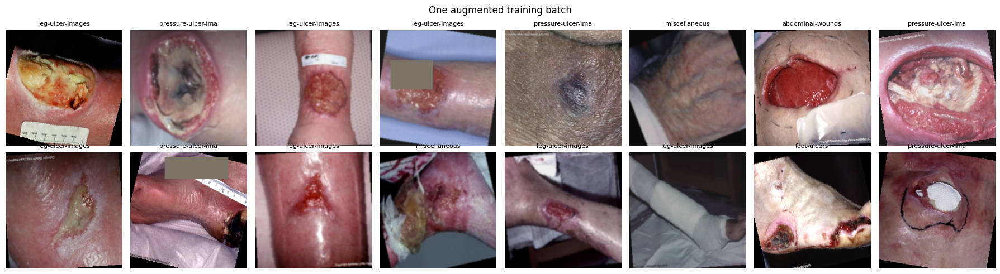

In [12]:
class WoundDS(Dataset):
    def __init__(self, paths, ys, tf):
        self.paths, self.ys, self.tf = list(paths), np.asarray(ys), tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB")), int(self.ys[i])

def make_loader(d, tf, shuffle):
    return DataLoader(WoundDS(d.path.values, d.y.values, tf), batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=(DEVICE == "cuda"),
                      drop_last=shuffle and len(d) > BATCH_SIZE)

train_loader = make_loader(train_df, train_tf, True)
val_loader   = make_loader(val_df,   eval_tf,  False)
test_loader  = make_loader(test_df,  eval_tf,  False)

xb, yb = next(iter(train_loader))
print("Batch:", tuple(xb.shape), "| train/val/test batches:", len(train_loader), len(val_loader), len(test_loader))
fig, axes = plt.subplots(2, 8, figsize=(18, 5))
for ax, x, y in zip(axes.flat, xb, yb):
    ax.imshow(denorm(x)); ax.set_title(CLASSES[y][:18], fontsize=8); ax.axis("off")
plt.suptitle("One augmented training batch"); plt.tight_layout(); plt.show()

In [14]:
class HybridWoundNet(nn.Module):
    def __init__(self, n_classes, use_mnv3=True, use_effb0=True, use_transformer=True,
                 dim=256, depth=2, heads=4, drop=0.3, img_size=IMG_SIZE, pretrained=True):
        super().__init__()
        assert use_mnv3 or use_effb0
        self.use_mnv3, self.use_effb0, self.use_transformer = use_mnv3, use_effb0, use_transformer
        if use_mnv3:
            w = models.MobileNet_V3_Large_Weights.IMAGENET1K_V2 if pretrained else None
            self.b1 = models.mobilenet_v3_large(weights=w).features
            self.p1 = nn.Sequential(nn.Conv2d(960, dim, 1, bias=False), nn.BatchNorm2d(dim), nn.GELU())
        if use_effb0:
            w = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
            self.b2 = models.efficientnet_b0(weights=w).features
            self.p2 = nn.Sequential(nn.Conv2d(1280, dim, 1, bias=False), nn.BatchNorm2d(dim), nn.GELU())
        if use_mnv3 and use_effb0:
            self.gate = nn.Sequential(nn.Linear(2 * dim, dim // 4), nn.ReLU(inplace=True), nn.Linear(dim // 4, 2))
        self.fuse_out = nn.Identity()            # Grad-CAM target layer
        if use_transformer:
            n_tok = (img_size // 32) ** 2
            self.cls_tok = nn.Parameter(torch.zeros(1, 1, dim))
            self.pos = nn.Parameter(torch.zeros(1, n_tok + 1, dim))
            nn.init.trunc_normal_(self.cls_tok, std=0.02); nn.init.trunc_normal_(self.pos, std=0.02)
            layer = nn.TransformerEncoderLayer(dim, heads, dim * 2, dropout=0.1, activation="gelu",
                                               batch_first=True, norm_first=True)
            self.tr = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
            self.norm = nn.LayerNorm(dim)
        self.head = nn.Sequential(nn.Dropout(drop), nn.Linear(dim * (2 if use_transformer else 1), n_classes))

    def backbone_params(self):
        ps = []
        if self.use_mnv3:  ps += list(self.b1.parameters())
        if self.use_effb0: ps += list(self.b2.parameters())
        return ps

    def set_backbone_trainable(self, flag):
        for p in self.backbone_params():
            p.requires_grad = flag

    def forward(self, x):
        feats = []
        if self.use_mnv3:  feats.append(self.p1(self.b1(x)))
        if self.use_effb0: feats.append(self.p2(self.b2(x)))
        if len(feats) == 2:
            w = torch.softmax(self.gate(torch.cat([feats[0].mean((2, 3)), feats[1].mean((2, 3))], 1)), 1)
            f = w[:, 0, None, None, None] * feats[0] + w[:, 1, None, None, None] * feats[1]
        else:
            f = feats[0]
        f = self.fuse_out(f)
        gap = f.mean((2, 3))
        if not self.use_transformer:
            return self.head(gap)
        t = f.flatten(2).transpose(1, 2)
        t = torch.cat([self.cls_tok.expand(t.size(0), -1, -1), t], 1) + self.pos
        t = self.norm(self.tr(t))
        return self.head(torch.cat([t[:, 0], gap], 1))

def build_model(**kw):
    return HybridWoundNet(NUM_CLASSES, pretrained=PRETRAINED, **kw).to(DEVICE)

def n_params(m):
    return sum(p.numel() for p in m.parameters()) / 1e6

model = build_model()
print(f"Proposed hybrid model params: {n_params(model):.2f} M")

Proposed hybrid model params: 8.66 M


In [15]:
def make_criterion(ys):
    freq = np.bincount(ys, minlength=NUM_CLASSES).astype(float)
    w = (freq.sum() / (NUM_CLASSES * np.maximum(freq, 1))) ** 0.5
    return nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32, device=DEVICE), label_smoothing=0.1)

def run_epoch(model, loader, crit, opt=None, scaler=None):
    train = opt is not None
    model.train(train)
    tot, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.set_grad_enabled(train), torch.autocast(device_type="cuda", enabled=USE_AMP):
            out = model(x); loss = crit(out, y)
        if train:
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            scaler.step(opt); scaler.update()
        tot += loss.item() * x.size(0); correct += (out.argmax(1) == y).sum().item(); n += x.size(0)
    return tot / n, correct / n

def train_model(model, tr_loader, va_loader, save_path, epochs=EPOCHS, verbose=True):
    crit = make_criterion(tr_loader.dataset.ys)
    bb = {id(p) for p in model.backbone_params()}
    opt = torch.optim.AdamW([
        {"params": model.backbone_params(), "lr": LR_BACKBONE},
        {"params": [p for p in model.parameters() if id(p) not in bb], "lr": LR_HEAD},
    ], weight_decay=WEIGHT_DECAY)
    sched  = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=LR_FACTOR, patience=LR_PATIENCE, min_lr=1e-7)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    hist = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc", "lr"]}
    best, wait = np.inf, 0
    for ep in range(epochs):
        model.set_backbone_trainable(ep >= FREEZE_EPOCHS)
        t0 = time.time()
        tl, ta = run_epoch(model, tr_loader, crit, opt, scaler)
        vl, va = run_epoch(model, va_loader, crit)
        sched.step(vl)
        for k, v in zip(hist, [tl, vl, ta, va, opt.param_groups[1]["lr"]]):
            hist[k].append(v)
        msg = ""
        if vl < best - 1e-4:
            best, wait = vl, 0
            torch.save(model.state_dict(), save_path); msg = "  ✓ best saved"
        else:
            wait += 1
        if verbose:
            print(f"Ep {ep+1:02d} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f} | "
                  f"lr {opt.param_groups[1]['lr']:.1e} | {time.time()-t0:.0f}s{msg}")
        if wait >= PATIENCE:
            print(f"Early stopping at epoch {ep+1} (no val-loss improvement for {PATIENCE} epochs)"); break
    model.load_state_dict(torch.load(save_path, map_location=DEVICE))
    model.set_backbone_trainable(True)
    return hist

@torch.no_grad()
def predict(model, loader, tta=True):
    model.eval(); P, Y = [], []
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type="cuda", enabled=USE_AMP):
            p = F.softmax(model(x), 1)
            if tta:
                p = (p + F.softmax(model(torch.flip(x, [3])), 1)) / 2
        P.append(p.float().cpu()); Y.append(y)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

In [16]:
BEST_PATH = os.path.join(OUT_DIR, "best_hybrid_model.pth")
history = train_model(model, train_loader, val_loader, BEST_PATH)

Ep 01 | train loss 2.5518 acc 0.2083 | val loss 2.2388 acc 0.2706 | lr 1.0e-03 | 23s  ✓ best saved
Ep 02 | train loss 2.1214 acc 0.3906 | val loss 2.0348 acc 0.4000 | lr 1.0e-03 | 3s  ✓ best saved
Ep 03 | train loss 1.8440 acc 0.5052 | val loss 1.9546 acc 0.4824 | lr 1.0e-03 | 82s  ✓ best saved
Ep 04 | train loss 1.7027 acc 0.5651 | val loss 1.9124 acc 0.5059 | lr 1.0e-03 | 4s  ✓ best saved
Ep 05 | train loss 1.5514 acc 0.6198 | val loss 1.7540 acc 0.4706 | lr 1.0e-03 | 4s  ✓ best saved
Ep 06 | train loss 1.3665 acc 0.7135 | val loss 1.7586 acc 0.5294 | lr 1.0e-03 | 4s
Ep 07 | train loss 1.3139 acc 0.7161 | val loss 1.6784 acc 0.6471 | lr 1.0e-03 | 4s  ✓ best saved
Ep 08 | train loss 1.2529 acc 0.7526 | val loss 1.7442 acc 0.5529 | lr 1.0e-03 | 4s
Ep 09 | train loss 1.1281 acc 0.7839 | val loss 1.7894 acc 0.6000 | lr 1.0e-03 | 4s
Ep 10 | train loss 1.0788 acc 0.8281 | val loss 1.7942 acc 0.5412 | lr 5.0e-04 | 4s
Ep 11 | train loss 0.9730 acc 0.8750 | val loss 1.8183 acc 0.5412 | lr 5.0

Best model loaded from: /kaggle/working/best_hybrid_model.pth


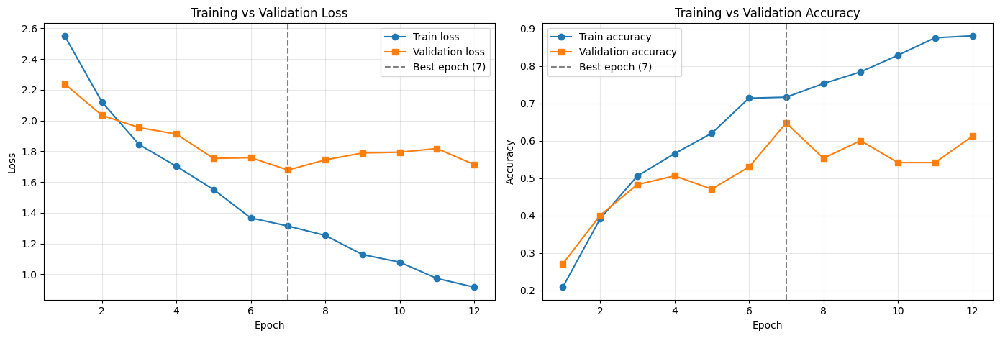

In [17]:
model = build_model()
model.load_state_dict(torch.load(BEST_PATH, map_location=DEVICE))
model.eval()
print("Best model loaded from:", BEST_PATH)

ep_ax = range(1, len(history["train_loss"]) + 1)
best_ep = int(np.argmin(history["val_loss"])) + 1
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].plot(ep_ax, history["train_loss"], "o-", label="Train loss")
ax[0].plot(ep_ax, history["val_loss"], "s-", label="Validation loss")
ax[1].plot(ep_ax, history["train_acc"], "o-", label="Train accuracy")
ax[1].plot(ep_ax, history["val_acc"], "s-", label="Validation accuracy")
for a, t in zip(ax, ["Loss", "Accuracy"]):
    a.axvline(best_ep, ls="--", c="gray", label=f"Best epoch ({best_ep})")
    a.set_xlabel("Epoch"); a.set_ylabel(t); a.set_title(f"Training vs Validation {t}"); a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "loss_accuracy_curves.png"), dpi=150); plt.show()

In [18]:
def compute_metrics(y, probs):
    pred = probs.argmax(1)
    y_bin = label_binarize(y, classes=range(NUM_CLASSES))
    if NUM_CLASSES == 2:
        y_bin = np.column_stack([1 - y_bin[:, 0], y_bin[:, 0]])
    mcm = multilabel_confusion_matrix(y, pred, labels=range(NUM_CLASSES))
    rows = []
    for c in range(NUM_CLASSES):
        tn, fp, fn, tp = mcm[c].ravel()
        prec = tp / (tp + fp) if tp + fp else 0.0
        rec  = tp / (tp + fn) if tp + fn else 0.0
        f1   = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
        spec = tn / (tn + fp) if tn + fp else 0.0
        try:
            auc_c = roc_auc_score(y_bin[:, c], probs[:, c])
        except ValueError:
            auc_c = np.nan
        rows.append([CLASSES[c], (tp + tn) / mcm[c].sum(), prec, rec, f1, auc_c, rec, spec, tp + fn])
    cols = ["Class", "Accuracy", "Precision", "Recall", "F1-score", "AUC", "Sensitivity", "Specificity", "Support"]
    per = pd.DataFrame(rows, columns=cols)
    sup = per.Support.values
    macro = ["Overall (macro)", accuracy_score(y, pred)] + [np.nanmean(per[c]) for c in cols[2:8]] + [sup.sum()]
    wavg  = ["Overall (weighted)", accuracy_score(y, pred)] + \
            [np.nansum(per[c] * sup) / sup.sum() for c in cols[2:8]] + [sup.sum()]
    full = pd.concat([per, pd.DataFrame([macro, wavg], columns=cols)], ignore_index=True)
    return full, dict(zip(cols[1:8], macro[1:8]))

val_probs,  val_y  = predict(model, val_loader)
test_probs, test_y = predict(model, test_loader)
val_pred, test_pred = val_probs.argmax(1), test_probs.argmax(1)

reports = {}
for name, y, p in [("Validation", val_y, val_probs), ("Test", test_y, test_probs)]:
    rep, summ = compute_metrics(y, p)
    reports[name] = summ
    print(f"\n================  {name.upper()} SET  ================")
    print(f"Accuracy {summ['Accuracy']:.4f} | Precision {summ['Precision']:.4f} | Recall {summ['Recall']:.4f} | "
          f"F1 {summ['F1-score']:.4f} | AUC {summ['AUC']:.4f} | Sensitivity {summ['Sensitivity']:.4f} | Specificity {summ['Specificity']:.4f}")
    display(rep.style.format({c: "{:.4f}" for c in rep.columns[1:8]}).background_gradient(subset=["F1-score"], cmap="Greens"))
    rep.to_csv(os.path.join(OUT_DIR, f"classification_report_{name.lower()}.csv"), index=False)
    print(classification_report(y, p.argmax(1), labels=range(NUM_CLASSES), target_names=CLASSES, digits=4, zero_division=0))


================  VALIDATION SET  ================
Accuracy 0.6118 | Precision 0.6343 | Recall 0.5464 | F1 0.5424 | AUC 0.9097 | Sensitivity 0.5464 | Specificity 0.9609


,Class,Accuracy,Precision,Recall,F1-score,AUC,Sensitivity,Specificity,Support
0,abdominal-wounds,0.9765,0.0000,0.0000,0.0000,0.9639,0.0000,1.0000,2
1,burns,0.8706,0.1667,0.6667,0.2667,0.9350,0.6667,0.8780,3
2,extravasation-wound-images,0.9882,1.0000,0.6667,0.8000,0.9350,0.6667,1.0000,3
3,foot-ulcers,0.9294,0.5714,0.5714,0.5714,0.9231,0.5714,0.9615,7
4,leg-ulcer-images,0.9412,0.9412,0.8000,0.8649,0.9662,0.8000,0.9846,20
5,meningitis,0.9647,1.0000,0.2500,0.4000,0.9012,0.2500,1.0000,4
6,miscellaneous,0.8471,0.2727,0.3750,0.3158,0.6786,0.3750,0.8961,8
7,orthopaedic-wounds,0.9647,1.0000,0.5714,0.7273,0.8626,0.5714,1.0000,7
8,pressure-ulcer-images-a,0.8471,0.6000,0.4000,0.4800,0.8867,0.4000,0.9429,15
9,pressure-ulcer-images-b,0.9176,0.6250,0.9091,0.7407,0.9619,0.9091,0.9189,11


                            precision    recall  f1-score   support

          abdominal-wounds     0.0000    0.0000    0.0000         2
                     burns     0.1667    0.6667    0.2667         3
extravasation-wound-images     1.0000    0.6667    0.8000         3
               foot-ulcers     0.5714    0.5714    0.5714         7
          leg-ulcer-images     0.9412    0.8000    0.8649        20
                meningitis     1.0000    0.2500    0.4000         4
             miscellaneous     0.2727    0.3750    0.3158         8
        orthopaedic-wounds     1.0000    0.5714    0.7273         7
   pressure-ulcer-images-a     0.6000    0.4000    0.4800        15
   pressure-ulcer-images-b     0.6250    0.9091    0.7407        11
                      toes     0.8000    0.8000    0.8000         5

                  accuracy                         0.6118        85
                 macro avg     0.6343    0.5464    0.5424        85
              weighted avg     0.6986    0.611

,Class,Accuracy,Precision,Recall,F1-score,AUC,Sensitivity,Specificity,Support
0,abdominal-wounds,0.9884,1.0000,0.5000,0.6667,0.9940,0.5000,1.0000,2
1,burns,0.9419,0.3750,1.0000,0.5455,1.0000,1.0000,0.9398,3
2,extravasation-wound-images,0.9767,0.5000,0.5000,0.5000,0.8690,0.5000,0.9881,2
3,foot-ulcers,0.8488,0.2500,0.4286,0.3158,0.8897,0.4286,0.8861,7
4,leg-ulcer-images,0.8721,0.7083,0.8095,0.7556,0.9216,0.8095,0.8923,21
5,meningitis,0.9651,0.0000,0.0000,0.0000,0.7671,0.0000,1.0000,3
6,miscellaneous,0.9186,0.7500,0.3333,0.4615,0.7965,0.3333,0.9870,9
7,orthopaedic-wounds,0.9186,0.6000,0.3750,0.4615,0.8429,0.3750,0.9744,8
8,pressure-ulcer-images-a,0.8372,0.5714,0.2667,0.3636,0.8986,0.2667,0.9577,15
9,pressure-ulcer-images-b,0.8953,0.5556,0.9091,0.6897,0.9394,0.9091,0.8933,11


                            precision    recall  f1-score   support

          abdominal-wounds     1.0000    0.5000    0.6667         2
                     burns     0.3750    1.0000    0.5455         3
extravasation-wound-images     0.5000    0.5000    0.5000         2
               foot-ulcers     0.2500    0.4286    0.3158         7
          leg-ulcer-images     0.7083    0.8095    0.7556        21
                meningitis     0.0000    0.0000    0.0000         3
             miscellaneous     0.7500    0.3333    0.4615         9
        orthopaedic-wounds     0.6000    0.3750    0.4615         8
   pressure-ulcer-images-a     0.5714    0.2667    0.3636        15
   pressure-ulcer-images-b     0.5556    0.9091    0.6897        11
                      toes     0.8000    0.8000    0.8000         5

                  accuracy                         0.5698        86
                 macro avg     0.5555    0.5384    0.5054        86
              weighted avg     0.5928    0.569

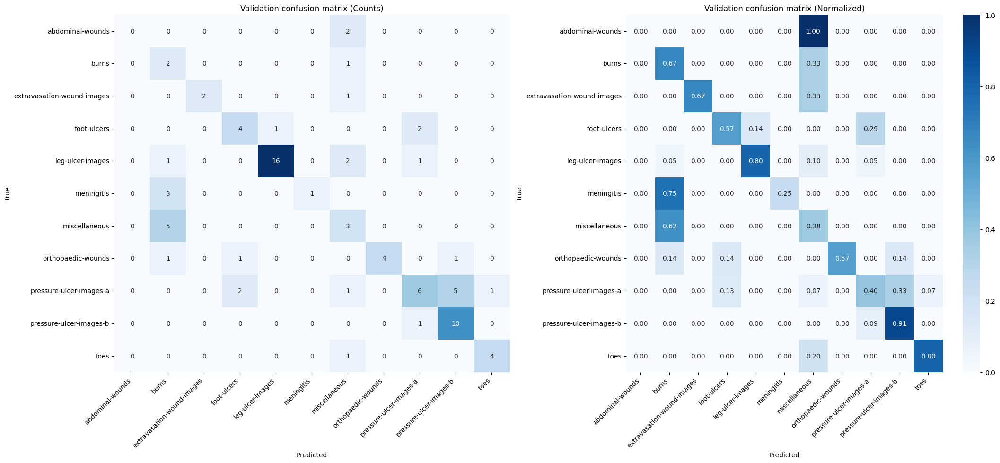

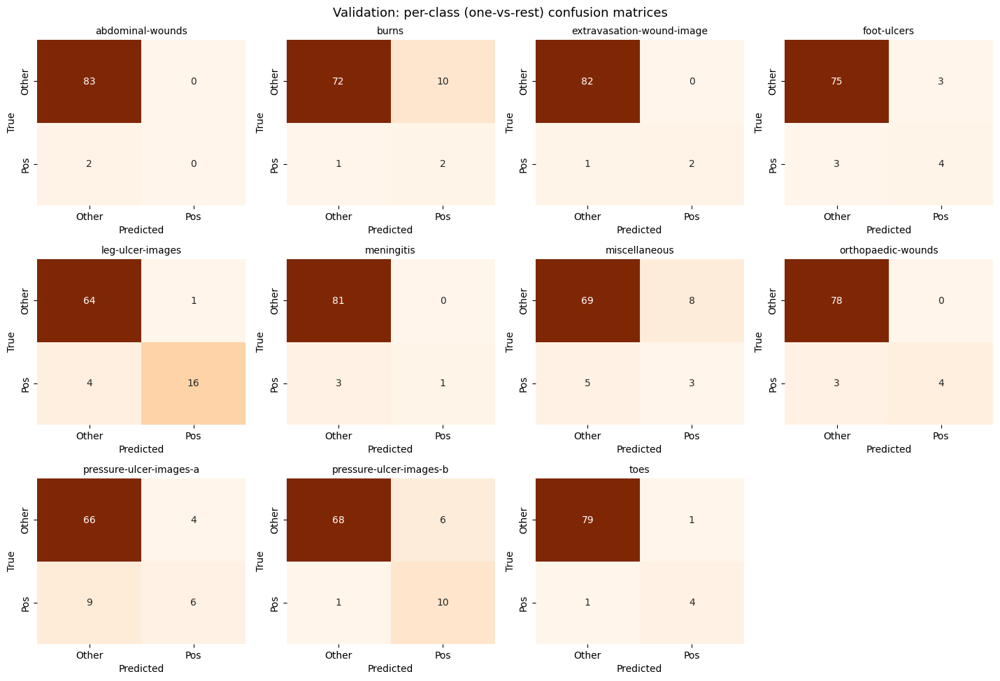

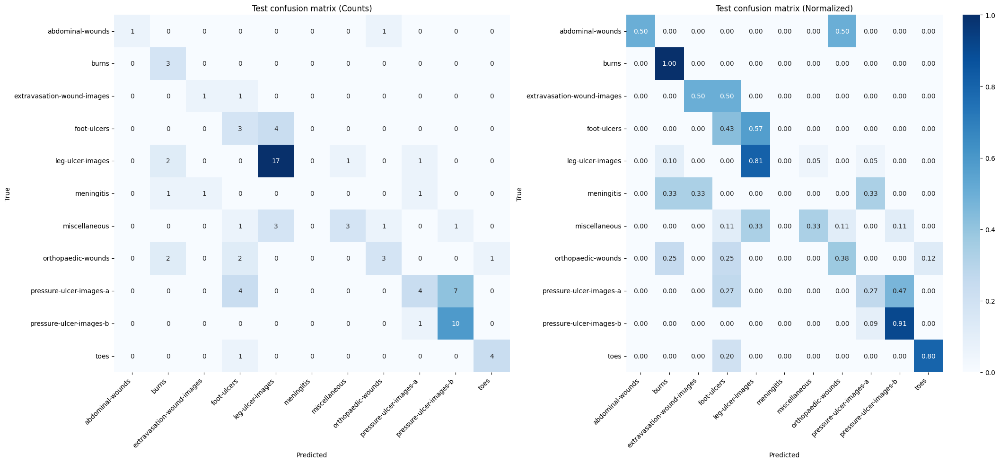

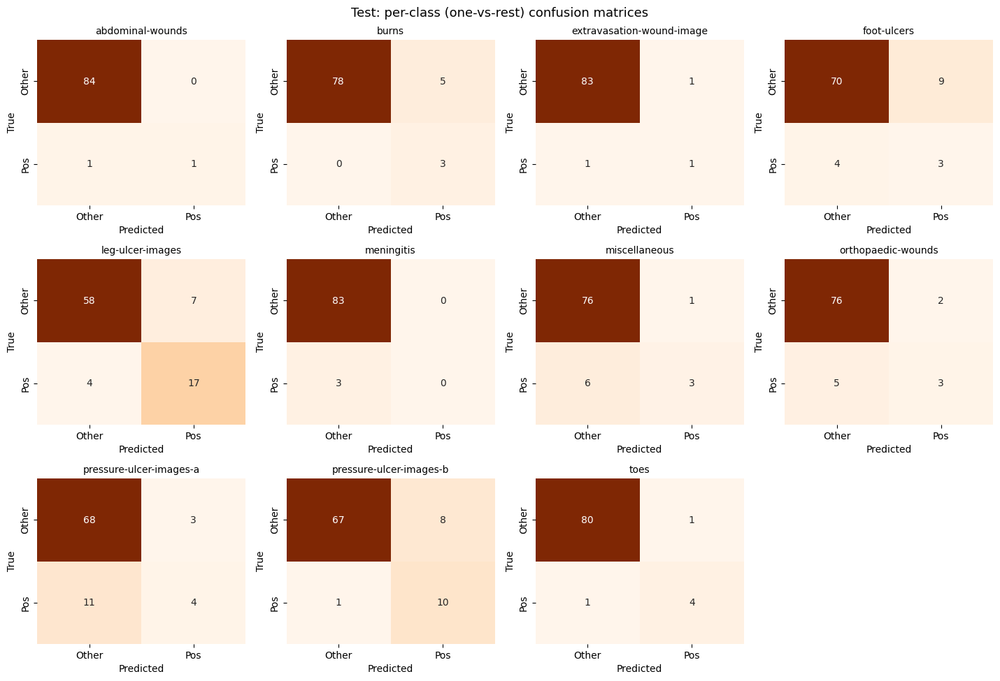

In [19]:
for name, y, pred in [("Validation", val_y, val_pred), ("Test", test_y, test_pred)]:
    cm = confusion_matrix(y, pred, labels=range(NUM_CLASSES))
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    s = max(6, NUM_CLASSES * 0.9)
    fig, ax = plt.subplots(1, 2, figsize=(2 * s + 2, s))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0], cbar=False)
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1], vmin=0, vmax=1)
    for a, t in zip(ax, ["Counts", "Normalized"]):
        a.set_xlabel("Predicted"); a.set_ylabel("True"); a.set_title(f"{name} confusion matrix ({t})")
        a.set_xticklabels(a.get_xticklabels(), rotation=45, ha="right")
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"cm_overall_{name.lower()}.png"), dpi=150); plt.show()

    mcm = multilabel_confusion_matrix(y, pred, labels=range(NUM_CLASSES))
    ncol = min(4, NUM_CLASSES); nrow = int(np.ceil(NUM_CLASSES / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.6 * ncol, 3.3 * nrow))
    axes = np.array(axes).reshape(-1)
    for a in axes: a.axis("off")
    for c in range(NUM_CLASSES):
        axes[c].axis("on")
        sns.heatmap(mcm[c], annot=True, fmt="d", cmap="Oranges", cbar=False, ax=axes[c],
                    xticklabels=["Other", "Pos"], yticklabels=["Other", "Pos"])
        axes[c].set_title(CLASSES[c][:25], fontsize=10); axes[c].set_xlabel("Predicted"); axes[c].set_ylabel("True")
    plt.suptitle(f"{name}: per-class (one-vs-rest) confusion matrices", fontsize=13)
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"cm_perclass_{name.lower()}.png"), dpi=150); plt.show()

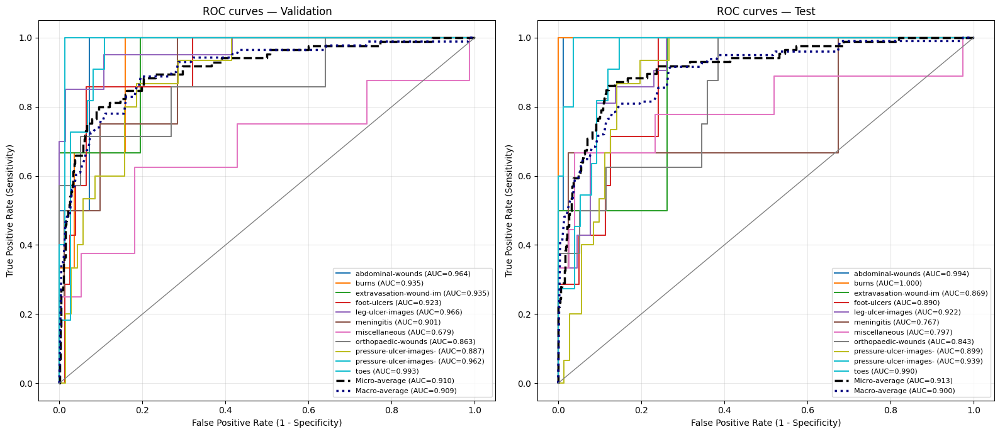

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
colors = plt.cm.tab10(np.linspace(0, 1, max(NUM_CLASSES, 2)))
for ax, (name, y, p) in zip(axes, [("Validation", val_y, val_probs), ("Test", test_y, test_probs)]):
    y_bin = label_binarize(y, classes=range(NUM_CLASSES))
    if NUM_CLASSES == 2:
        y_bin = np.column_stack([1 - y_bin[:, 0], y_bin[:, 0]])
    grid, tprs = np.linspace(0, 1, 200), []
    for c in range(NUM_CLASSES):
        if y_bin[:, c].sum() in (0, len(y)):
            continue
        fpr, tpr, _ = roc_curve(y_bin[:, c], p[:, c])
        tprs.append(np.interp(grid, fpr, tpr))
        ax.plot(fpr, tpr, color=colors[c], lw=1.5, label=f"{CLASSES[c][:22]} (AUC={auc(fpr, tpr):.3f})")
    fpr, tpr, _ = roc_curve(y_bin.ravel(), p.ravel())
    ax.plot(fpr, tpr, "k--", lw=2.5, label=f"Micro-average (AUC={auc(fpr, tpr):.3f})")
    if tprs:
        mt = np.mean(tprs, 0); mt[0] = 0
        ax.plot(grid, mt, color="navy", ls=":", lw=2.5, label=f"Macro-average (AUC={auc(grid, mt):.3f})")
    ax.plot([0, 1], [0, 1], color="gray", lw=1)
    ax.set_xlabel("False Positive Rate (1 - Specificity)"); ax.set_ylabel("True Positive Rate (Sensitivity)")
    ax.set_title(f"ROC curves — {name}"); ax.legend(fontsize=8, loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "roc_curves.png"), dpi=150); plt.show()

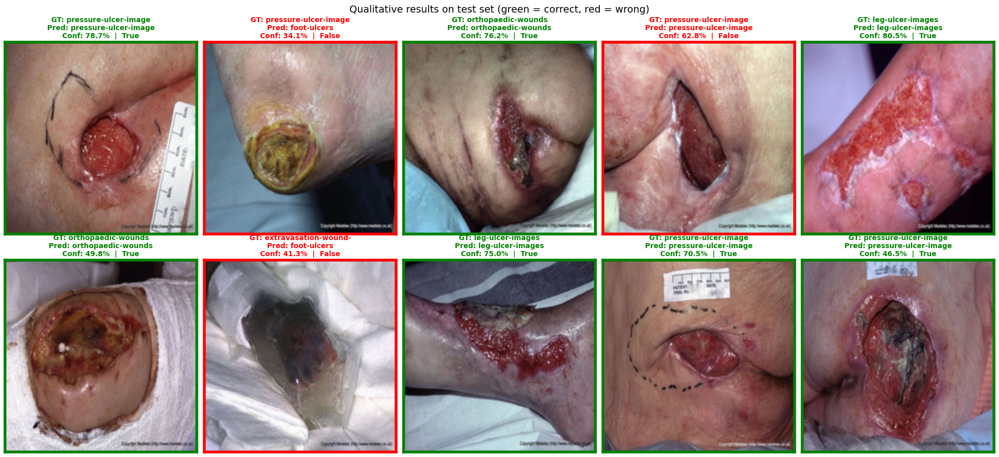

In [21]:
rng = np.random.default_rng(SEED)
wrong = np.where(test_pred != test_y)[0]; right = np.where(test_pred == test_y)[0]
n_r = min(10 - min(3, len(wrong)), len(right)); n_w = min(10 - n_r, len(wrong))
XAI_IDX = np.concatenate([rng.choice(wrong, n_w, replace=False), rng.choice(right, n_r, replace=False)]).astype(int)
rng.shuffle(XAI_IDX)

def sample_info(i):
    img = np.array(disp_tf(Image.open(test_df.path[i]).convert("RGB")))
    gt, pr = test_y[i], test_pred[i]
    ok = gt == pr
    txt = f"GT: {CLASSES[gt][:20]}\nPred: {CLASSES[pr][:20]}\nConf: {test_probs[i, pr]*100:.1f}%  |  {'True' if ok else 'False'}"
    return img, txt, ("green" if ok else "red"), pr

fig, axes = plt.subplots(2, 5, figsize=(20, 9.5))
for ax in axes.flat: ax.axis("off")
for ax, i in zip(axes.flat, XAI_IDX):
    img, txt, col, _ = sample_info(i)
    ax.imshow(img); ax.set_title(txt, color=col, fontsize=10, fontweight="bold")
    for s in ax.spines.values(): s.set_edgecolor(col); s.set_linewidth(4)
    ax.axis("on"); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Qualitative results on test set (green = correct, red = wrong)", fontsize=14)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "qualitative_results.png"), dpi=150); plt.show()

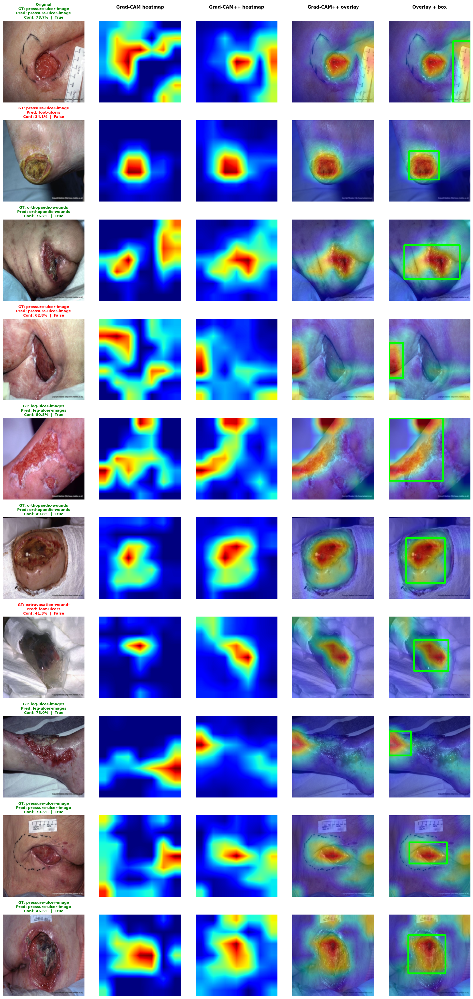

In [22]:
class CAM:
    def __init__(self, model, layer):
        self.model, self.act, self.grad = model, None, None
        self.h = layer.register_forward_hook(self._hook)
    def _hook(self, m, i, o):
        self.act = o
        o.register_hook(lambda g: setattr(self, "grad", g))
    @staticmethod
    def _norm(c):
        c = cv2.resize(c.cpu().numpy(), (IMG_SIZE, IMG_SIZE))
        return (c - c.min()) / (c.max() - c.min() + 1e-8)
    def __call__(self, x, cls):
        self.model.eval(); self.model.zero_grad()
        with torch.enable_grad():
            self.model(x)[0, cls].backward()
        A, G = self.act.detach()[0].float(), self.grad.detach()[0].float()
        cam = F.relu((G.mean((1, 2))[:, None, None] * A).sum(0))                       # Grad-CAM
        g2, g3 = G ** 2, G ** 3
        alpha = g2 / (2 * g2 + A.sum((1, 2), keepdim=True) * g3 + 1e-7)
        alpha = torch.where(G != 0, alpha, torch.zeros_like(alpha))
        campp = F.relu(((alpha * F.relu(G)).sum((1, 2))[:, None, None] * A).sum(0))     # Grad-CAM++
        return self._norm(cam), self._norm(campp)
    def remove(self):
        self.h.remove()

def overlay(img, cam, a=0.45):
    heat = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    return np.uint8((1 - a) * img + a * heat)

def draw_box(img, cam, thr=0.5):
    out = img.copy()
    cnts = cv2.findContours((cam >= thr).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[-2]
    if cnts:
        x, y, w, h = cv2.boundingRect(max(cnts, key=cv2.contourArea))
        cv2.rectangle(out, (x, y), (x + w, y + h), (0, 255, 0), 3)
    return out

model.set_backbone_trainable(True)
cam_ext = CAM(model, model.fuse_out)
cols = ["Original", "Grad-CAM heatmap", "Grad-CAM++ heatmap", "Grad-CAM++ overlay", "Overlay + box"]
fig, axes = plt.subplots(len(XAI_IDX), 5, figsize=(17, 3.5 * len(XAI_IDX)))
axes = np.atleast_2d(axes)
for r, i in enumerate(XAI_IDX):
    img, txt, col, pr = sample_info(i)
    x = eval_tf(Image.open(test_df.path[i]).convert("RGB")).unsqueeze(0).to(DEVICE)
    cam, campp = cam_ext(x, int(pr))
    ims = [img, cam, campp, overlay(img, campp), draw_box(overlay(img, campp), campp)]
    for c, (ax, im) in enumerate(zip(axes[r], ims)):
        ax.imshow(im, cmap="jet" if c in (1, 2) else None); ax.axis("off")
        if r == 0: ax.set_title(cols[c] + ("\n\n" if c else ""), fontsize=11, fontweight="bold")
    axes[r, 0].set_title(("Original\n" if r == 0 else "") + txt, color=col, fontsize=9, fontweight="bold")
cam_ext.remove()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "gradcam_results.png"), dpi=120); plt.show()

  0%|          | 0/600 [00:00<?, ?it/s]

  0%|          | 0/600 [00:00<?, ?it/s]

  0%|          | 0/600 [00:00<?, ?it/s]

  0%|          | 0/600 [00:00<?, ?it/s]

  0%|          | 0/600 [00:00<?, ?it/s]

  0%|          | 0/600 [00:00<?, ?it/s]

  0%|          | 0/600 [00:00<?, ?it/s]

  0%|          | 0/600 [00:00<?, ?it/s]

  0%|          | 0/600 [00:00<?, ?it/s]

  0%|          | 0/600 [00:00<?, ?it/s]

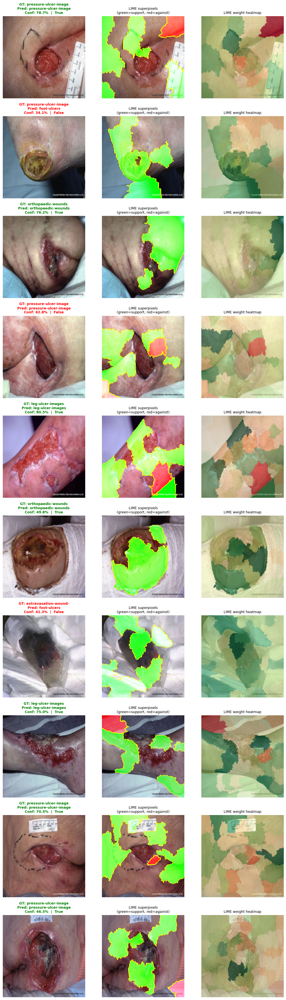

In [23]:
from lime import lime_image
from skimage.segmentation import mark_boundaries

@torch.no_grad()
def lime_predict(images):
    x = torch.tensor(images, dtype=torch.float32).permute(0, 3, 1, 2)
    x = (x - torch.tensor(MEAN)[None, :, None, None]) / torch.tensor(STD)[None, :, None, None]
    model.eval(); out = []
    for b in torch.split(x, 32):
        out.append(F.softmax(model(b.to(DEVICE)), 1).cpu())
    return torch.cat(out).numpy()

explainer = lime_image.LimeImageExplainer(random_state=SEED)
fig, axes = plt.subplots(len(XAI_IDX), 3, figsize=(11, 3.6 * len(XAI_IDX)))
axes = np.atleast_2d(axes)
for r, i in enumerate(XAI_IDX):
    img, txt, col, pr = sample_info(i)
    exp = explainer.explain_instance(img.astype(np.float64) / 255.0, lime_predict, labels=(int(pr),),
                                     top_labels=None, hide_color=0, num_samples=LIME_SAMPLES, random_seed=SEED)
    temp, mask = exp.get_image_and_mask(int(pr), positive_only=False, num_features=8, hide_rest=False)
    weights = dict(exp.local_exp[int(pr)])
    heat = np.vectorize(lambda s: weights.get(s, 0.0))(exp.segments)
    v = np.abs(heat).max() + 1e-8
    axes[r, 0].imshow(img); axes[r, 0].set_title(txt, color=col, fontsize=9, fontweight="bold")
    axes[r, 1].imshow(mark_boundaries(temp, mask)); axes[r, 1].set_title("LIME superpixels\n(green=support, red=against)", fontsize=9)
    axes[r, 2].imshow(img); axes[r, 2].imshow(heat, cmap="RdYlGn", vmin=-v, vmax=v, alpha=0.55); axes[r, 2].set_title("LIME weight heatmap", fontsize=9)
    for a in axes[r]: a.axis("off")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "lime_results.png"), dpi=120); plt.show()

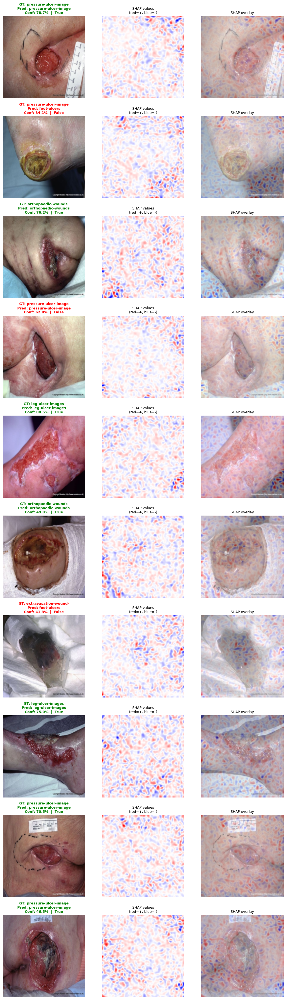

In [24]:
import shap

bg_idx = np.random.default_rng(SEED).choice(len(train_df), min(16, len(train_df)), replace=False)
background = torch.stack([eval_tf(Image.open(train_df.path[j]).convert("RGB")) for j in bg_idx]).to(DEVICE)
model.eval()
shap_exp = shap.GradientExplainer(model, background)

fig, axes = plt.subplots(len(XAI_IDX), 3, figsize=(11, 3.6 * len(XAI_IDX)))
axes = np.atleast_2d(axes)
for r, i in enumerate(XAI_IDX):
    img, txt, col, pr = sample_info(i)
    x = eval_tf(Image.open(test_df.path[i]).convert("RGB")).unsqueeze(0).to(DEVICE)
    sv = shap_exp.shap_values(x, nsamples=SHAP_NSAMPLES, rseed=SEED)
    sv = sv[int(pr)] if isinstance(sv, list) else sv[..., int(pr)]
    smap = np.asarray(sv)[0].sum(0)
    smap = cv2.GaussianBlur(smap.astype(np.float32), (0, 0), 3)
    v = np.abs(smap).max() + 1e-8
    axes[r, 0].imshow(img); axes[r, 0].set_title(txt, color=col, fontsize=9, fontweight="bold")
    axes[r, 1].imshow(smap, cmap="bwr", vmin=-v, vmax=v); axes[r, 1].set_title("SHAP values\n(red=+, blue=-)", fontsize=9)
    axes[r, 2].imshow(img); axes[r, 2].imshow(smap, cmap="bwr", vmin=-v, vmax=v, alpha=0.5); axes[r, 2].set_title("SHAP overlay", fontsize=9)
    for a in axes[r]: a.axis("off")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "shap_results.png"), dpi=120); plt.show()


########## FOLD 1/5 ##########
Early stopping at epoch 18 (no val-loss improvement for 5 epochs)
{'Accuracy': 0.5876, 'Precision': 0.5167, 'Recall': 0.4899, 'F1-score': 0.4759, 'AUC': 0.9044, 'Sensitivity': 0.4899, 'Specificity': 0.9567}

########## FOLD 2/5 ##########
Early stopping at epoch 13 (no val-loss improvement for 5 epochs)
{'Accuracy': 0.6082, 'Precision': 0.5828, 'Recall': 0.5855, 'F1-score': 0.5682, 'AUC': 0.9383, 'Sensitivity': 0.5855, 'Specificity': 0.9591}

########## FOLD 3/5 ##########
Early stopping at epoch 19 (no val-loss improvement for 5 epochs)
{'Accuracy': 0.6701, 'Precision': 0.7299, 'Recall': 0.6686, 'F1-score': 0.6856, 'AUC': 0.9169, 'Sensitivity': 0.6686, 'Specificity': 0.9654}

########## FOLD 4/5 ##########
Early stopping at epoch 11 (no val-loss improvement for 5 epochs)
{'Accuracy': 0.5729, 'Precision': 0.6021, 'Recall': 0.6002, 'F1-score': 0.5534, 'AUC': 0.9282, 'Sensitivity': 0.6002, 'Specificity': 0.9561}

########## FOLD 5/5 ##########
Early stoppi

,Fold,Accuracy,Precision,Recall,F1-score,AUC,Sensitivity,Specificity
0,Fold 1,0.5876,0.5167,0.4899,0.4759,0.9044,0.4899,0.9567
1,Fold 2,0.6082,0.5828,0.5855,0.5682,0.9383,0.5855,0.9591
2,Fold 3,0.6701,0.7299,0.6686,0.6856,0.9169,0.6686,0.9654
3,Fold 4,0.5729,0.6021,0.6002,0.5534,0.9282,0.6002,0.9561
4,Fold 5,0.4896,0.4470,0.4819,0.4226,0.8772,0.4819,0.9472
5,Mean,0.5857,0.5757,0.5652,0.5411,0.9130,0.5652,0.9569
6,Std,0.0653,0.1055,0.0790,0.1001,0.0237,0.0790,0.0065


K-fold ensemble on TEST: {'Accuracy': 0.686, 'Precision': 0.7029, 'Recall': 0.6189, 'F1-score': 0.6222, 'AUC': 0.9226, 'Sensitivity': 0.6189, 'Specificity': 0.9668}


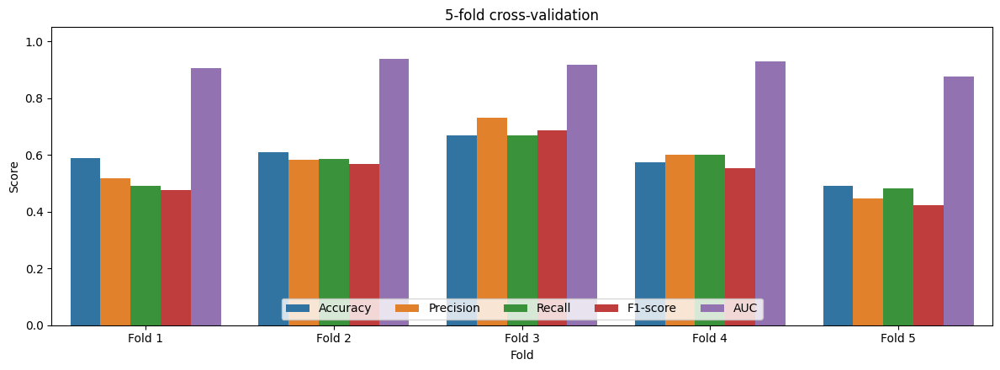

In [25]:
trval_df = pd.concat([train_df, val_df], ignore_index=True)
skf = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED)
fold_rows, fold_test_probs = [], []
for fold, (tr, va) in enumerate(skf.split(trval_df, trval_df.y)):
    print(f"\n########## FOLD {fold+1}/{N_FOLDS} ##########")
    seed_everything(SEED + fold)
    fm = build_model()
    fpath = os.path.join(OUT_DIR, f"fold{fold+1}_best.pth")
    train_model(fm, make_loader(trval_df.iloc[tr], train_tf, True), make_loader(trval_df.iloc[va], eval_tf, False), fpath, verbose=False)
    p, y = predict(fm, make_loader(trval_df.iloc[va], eval_tf, False))
    _, s = compute_metrics(y, p)
    fold_rows.append({"Fold": f"Fold {fold+1}", **s})
    fold_test_probs.append(predict(fm, test_loader)[0])
    print({k: round(float(v), 4) for k, v in s.items()})
    del fm; torch.cuda.empty_cache()

kfold_df = pd.DataFrame(fold_rows)
num_cols = kfold_df.columns[1:]
kfold_df.loc[len(kfold_df)] = ["Mean"] + list(kfold_df[num_cols].mean())
kfold_df.loc[len(kfold_df)] = ["Std"]  + list(kfold_df.iloc[:-1][num_cols].std())
display(kfold_df.style.format({c: "{:.4f}" for c in num_cols}))
kfold_df.to_csv(os.path.join(OUT_DIR, "kfold_results.csv"), index=False)

_, ens = compute_metrics(test_y, np.mean(fold_test_probs, 0))
print("K-fold ensemble on TEST:", {k: round(float(v), 4) for k, v in ens.items()})

plot_df = kfold_df.iloc[:N_FOLDS].melt(id_vars="Fold", value_vars=["Accuracy", "Precision", "Recall", "F1-score", "AUC"])
plt.figure(figsize=(12, 4.5)); sns.barplot(data=plot_df, x="Fold", y="value", hue="variable")
plt.ylim(0, 1.05); plt.ylabel("Score"); plt.title(f"{N_FOLDS}-fold cross-validation"); plt.legend(ncol=5, loc="lower center")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "kfold_results.png"), dpi=150); plt.show()


>>> MobileNetV3-L only
Early stopping at epoch 20 (no val-loss improvement for 5 epochs)
{'Accuracy': 0.6047, 'Precision': 0.6092, 'Recall': 0.5528, 'F1-score': 0.5649, 'AUC': 0.9365, 'Sensitivity': 0.5528, 'Specificity': 0.9575}

>>> EfficientNet-B0 only
Early stopping at epoch 15 (no val-loss improvement for 5 epochs)
{'Accuracy': 0.5814, 'Precision': 0.4739, 'Recall': 0.4945, 'F1-score': 0.4745, 'AUC': 0.9197, 'Sensitivity': 0.4945, 'Specificity': 0.9566}

>>> MobileNetV3 + Transformer
Early stopping at epoch 14 (no val-loss improvement for 5 epochs)
{'Accuracy': 0.6047, 'Precision': 0.521, 'Recall': 0.5429, 'F1-score': 0.5101, 'AUC': 0.9063, 'Sensitivity': 0.5429, 'Specificity': 0.9591}

>>> EfficientNet-B0 + Transformer
Early stopping at epoch 9 (no val-loss improvement for 5 epochs)
{'Accuracy': 0.5116, 'Precision': 0.4464, 'Recall': 0.443, 'F1-score': 0.4227, 'AUC': 0.8675, 'Sensitivity': 0.443, 'Specificity': 0.9496}

>>> Dual CNN + Gated Fusion (no Transformer)
Early stopping

,Model,Params (M),Accuracy,Precision,Recall,F1-score,AUC,Sensitivity,Specificity
0,MobileNetV3-L only,3.2211,0.6047,0.6092,0.5528,0.5649,0.9365,0.5528,0.9575
1,EfficientNet-B0 only,4.3386,0.5814,0.4739,0.4945,0.4745,0.9197,0.4945,0.9566
2,MobileNetV3 + Transformer,4.2916,0.6047,0.5210,0.5429,0.5101,0.9063,0.5429,0.9591
3,EfficientNet-B0 + Transformer,5.4092,0.5116,0.4464,0.4430,0.4227,0.8675,0.4430,0.9496
4,Dual CNN + Gated Fusion (no Transformer),7.5898,0.6395,0.5638,0.5432,0.5322,0.8923,0.5432,0.9623
5,Proposed w/o Augmentation,8.6603,0.4767,0.3700,0.3875,0.3219,0.8936,0.3875,0.9440
6,Proposed Hybrid (full),8.6603,0.5698,0.5555,0.5384,0.5054,0.9008,0.5384,0.9551


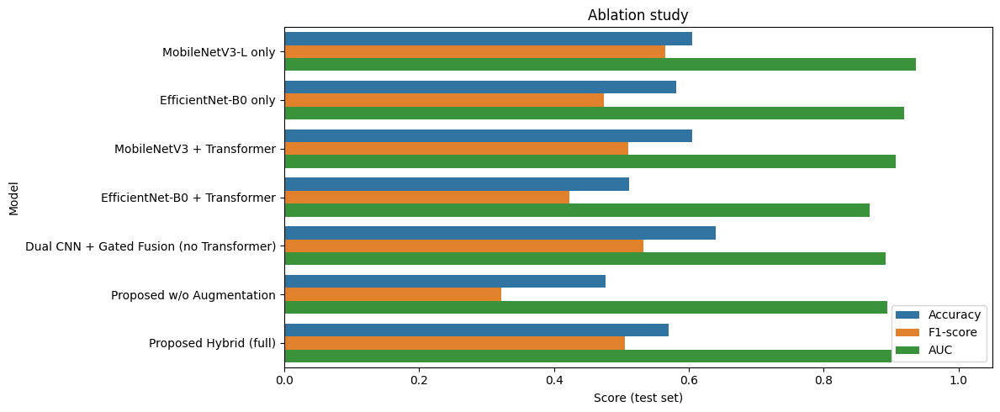

In [26]:
ABLATIONS = [
    ("MobileNetV3-L only",                      dict(use_mnv3=True,  use_effb0=False, use_transformer=False), True),
    ("EfficientNet-B0 only",                    dict(use_mnv3=False, use_effb0=True,  use_transformer=False), True),
    ("MobileNetV3 + Transformer",               dict(use_mnv3=True,  use_effb0=False, use_transformer=True),  True),
    ("EfficientNet-B0 + Transformer",           dict(use_mnv3=False, use_effb0=True,  use_transformer=True),  True),
    ("Dual CNN + Gated Fusion (no Transformer)", dict(use_mnv3=True,  use_effb0=True,  use_transformer=False), True),
    ("Proposed w/o Augmentation",               dict(use_mnv3=True,  use_effb0=True,  use_transformer=True),  False),
]
abl_rows = []
for name, kw, aug in ABLATIONS:
    print(f"\n>>> {name}")
    seed_everything()
    am = build_model(**kw)
    tr_loader = make_loader(train_df, train_tf if aug else eval_tf, True)
    train_model(am, tr_loader, val_loader, os.path.join(OUT_DIR, "ablation_tmp.pth"), verbose=False)
    _, s = compute_metrics(test_y, predict(am, test_loader)[0])
    abl_rows.append({"Model": name, "Params (M)": n_params(am), **s})
    print({k: round(float(v), 4) for k, v in s.items()})
    del am; torch.cuda.empty_cache()

abl_rows.append({"Model": "Proposed Hybrid (full)", "Params (M)": n_params(model), **reports["Test"]})
abl_df = pd.DataFrame(abl_rows)
display(abl_df.style.format({c: "{:.4f}" for c in abl_df.columns[1:]}).highlight_max(subset=["Accuracy", "F1-score", "AUC"], color="#b7e4c7"))
abl_df.to_csv(os.path.join(OUT_DIR, "ablation_results.csv"), index=False)

plt.figure(figsize=(12, 5))
sns.barplot(data=abl_df.melt(id_vars="Model", value_vars=["Accuracy", "F1-score", "AUC"]), y="Model", x="value", hue="variable")
plt.xlim(0, 1.05); plt.xlabel("Score (test set)"); plt.title("Ablation study"); plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "ablation_results.png"), dpi=150); plt.show()